# Evals — Main Agent

An eval is **test data + a grader + a loop**. Nothing more.

The test data is the course file `sms_conversations.json`. Every **recruiter**
turn carries a human label — `continue`, `schedule` or `end`. Candidate turns
carry `null`: they are input, not targets.

One eval item = the conversation history up to a labelled recruiter turn, and
the label that turn should get. The model never sees the turn it is predicting.

Order of work, and it matters: **the baseline is established before the model is
touched.** Without a number written down beforehand there is nothing to prove
afterwards.


In [1]:
import json, sys, warnings
from collections import Counter, defaultdict
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "tests" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd

from app.modules import config

conversations = json.loads(config.CONVERSATIONS_JSON.read_text(encoding="utf-8"))
print(f"{len(conversations)} conversations")
print(f"{sum(len(c['turns']) for c in conversations)} turns in total")

15 conversations
103 turns in total


## 1. Build the test set

In [2]:
def build_test_set(conversations):
    """One item per labelled recruiter turn: the history before it, and its label."""
    items = []
    for conversation in conversations:
        turns = conversation["turns"]
        for index, turn in enumerate(turns):
            if turn["label"]:
                items.append({
                    "conversation_id": conversation["conversation_id"],
                    "turn_id": turn["turn_id"],
                    "start_time_utc": conversation["start_time_utc"],
                    "history": turns[:index],
                    "correct_label": turn["label"],
                })
    return items

test_data = build_test_set(conversations)
distribution = Counter(item["correct_label"] for item in test_data)

print(f"eval items: {len(test_data)}")
for label, count in distribution.most_common():
    print(f"  {label:<9} {count:>3}  ({count/len(test_data):.1%})")

eval items: 59
  continue   25  (42.4%)
  schedule   19  (32.2%)
  end        15  (25.4%)


## 2. Baseline — before any model runs

The question a baseline answers: *how well does the dumbest possible system do?*
Here that is answering `continue` every single time.

In [3]:
majority_label, majority_count = distribution.most_common(1)[0]
baseline = majority_count / len(test_data)

print(f"baseline  (always '{majority_label}'):  {baseline:.2%}")
print(f"random    (1 of 3):                  {1/3:.2%}")
print()
print("The model has to beat the first number to be worth anything.")

baseline  (always 'continue'):  42.37%
random    (1 of 3):                  33.33%

The model has to beat the first number to be worth anything.


## 3. Ceiling — the labels disagree with themselves

Before blaming the model for errors, check whether the test data is answerable.
Identical candidate messages that lead to different labels put a hard cap on
accuracy: whichever way the model answers, one of them is marked wrong.

In [4]:
groups = defaultdict(list)
for item in test_data:
    last_candidate = next((turn["text"] for turn in reversed(item["history"])
                           if turn["speaker"] == "candidate"), None)
    if last_candidate:
        groups[last_candidate.strip().lower()].append(item)

unavoidable_errors = 0
for text, items in groups.items():
    labels = Counter(i["correct_label"] for i in items)
    if len(labels) > 1:
        unavoidable_errors += len(items) - max(labels.values())
        where = ", ".join(f"conv {i['conversation_id']}/turn {i['turn_id']}"
                          f" = {i['correct_label']}" for i in items)
        print(f'"{text[:58]}..."')
        print(f"    {where}\n")

ceiling = (len(test_data) - unavoidable_errors) / len(test_data)
print(f"unavoidable errors: {unavoidable_errors}")
print(f"ceiling: {ceiling:.2%} — a perfect model cannot score higher")

"i've been using python professionally for five years, most..."
    conv 1/turn 3 = schedule, conv 4/turn 3 = continue, conv 9/turn 3 = schedule

"i have three years' experience with django and flask...."
    conv 2/turn 3 = continue, conv 7/turn 3 = schedule

unavoidable errors: 2
ceiling: 96.61% — a perfect model cannot score higher


## 4. The grader

`normalize` pulls one of the three labels out of whatever the model actually
said, so `"schedule."` and `"The answer is schedule"` both count. `grade` is a
string check, operation `eq`.

In [5]:
from app.modules.main_agent import normalize

def grade(prediction, correct_label):
    """string_check - operation: eq"""
    return prediction == correct_label

for sample in ["schedule", "Schedule.", "The recruiter should continue.", "END", "maybe"]:
    print(f"{sample!r:<35} -> {normalize(sample)!r}")

'schedule'                          -> 'schedule'
'Schedule.'                         -> 'schedule'
'The recruiter should continue.'    -> 'continue'
'END'                               -> 'end'
'maybe'                             -> 'invalid'


### A second baseline: the turn number alone

The majority-class baseline ignores everything. A sharper question is how far
you get knowing only **how deep into the conversation you are**, and nothing of
what was said.

In [6]:
position_groups = defaultdict(list)
for item in test_data:
    candidate_turns = [t for t in item["history"] if t["speaker"] == "candidate"]
    position_groups[len(candidate_turns)].append(item["correct_label"])

best_by_position = sum(max(Counter(labels).values())
                       for labels in position_groups.values())
positional = best_by_position / len(test_data)

print(f"baseline, always 'continue'     {baseline:.2%}")
print(f"best possible from turn number  {positional:.2%}")
print()
for depth in sorted(position_groups):
    counts = Counter(position_groups[depth])
    print(f"  after {depth} candidate message(s): {dict(counts)}")

print()
print("The conversation's depth alone carries most of the signal. Whatever the")
print("model scores, the honest comparison is against this number, not against")
print(f"{baseline:.2%} — anything below {positional:.2%} is beaten by counting turns.")

baseline, always 'continue'     42.37%
best possible from turn number  71.19%

  after 0 candidate message(s): {'continue': 15}
  after 1 candidate message(s): {'schedule': 10, 'continue': 5}
  after 2 candidate message(s): {'schedule': 6, 'continue': 5, 'end': 4}
  after 3 candidate message(s): {'end': 8, 'schedule': 3}
  after 4 candidate message(s): {'end': 3}

The conversation's depth alone carries most of the signal. Whatever the
model scores, the honest comparison is against this number, not against
42.37% — anything below 71.19% is beaten by counting turns.


## 5. A reference without a model

Before writing a prompt, it is worth knowing how far plain rules get on this
data. `app/modules/rule_reference.py` is seven regular expressions. It costs
nothing and runs instantly.

In [7]:
from app.modules import rule_reference

rule_pred = [rule_reference.predict(item["history"]) for item in test_data]
rule_true = [item["correct_label"] for item in test_data]
rule_accuracy = sum(p == t for p, t in zip(rule_pred, rule_true)) / len(rule_true)

print(f"baseline (always continue)  {baseline:.2%}")
print(f"turn number alone           {positional:.2%}")
print(f"rules, no model             {rule_accuracy:.2%}")
print(f"ceiling                     {ceiling:.2%}")
print()
print("This is the number the prompt has to beat. A model scoring below it is")
print("not facing a hard task — it is being asked the wrong question.")

baseline (always continue)  42.37%
turn number alone           71.19%
rules, no model             88.14%
ceiling                     96.61%

This is the number the prompt has to beat. A model scoring below it is
not facing a hard task — it is being asked the wrong question.


## 6. The eval loop

Three prompt versions, scored against each other in one run.

- **v1** — the obvious reading of the three labels
- **v2** — v1 plus the decision rules the data actually follows
- **v3** — v2 plus paraphrased few-shot examples

The examples in v3 are written by hand, never copied from this test set, so
the comparison stays honest.

Cost: 3 × 59 requests, a few minutes and a few cents. `temperature=0` makes the
run repeatable.

In [8]:
from app.modules import main_agent

llm = main_agent.build_llm()
print("model:", config.CHAT_MODEL)

results = {}

for version, prompt in config.MAIN_AGENT_PROMPTS.items():
    predictions = []
    for index, item in enumerate(test_data):
        messages = main_agent.turns_to_messages(item["history"], prompt)
        if len(messages) == 1:
            prediction = "continue"            # nothing has been said yet
        else:
            prediction = normalize(llm.invoke(messages).content)
        predictions.append(prediction)
        if index % 20 == 0:
            print(f"  {version}  {index} / {len(test_data)}")
    results[version] = predictions
    hits = sum(p == t for p, t in zip(predictions, rule_true))
    print(f"  {version}  ->  {hits/len(rule_true):.2%}\n")

print("done")

model: gpt-4.1-mini
  v1  0 / 59


  v1  20 / 59


  v1  40 / 59


  v1  ->  50.85%

  v2  0 / 59


  v2  20 / 59


  v2  40 / 59


  v2  ->  83.05%

  v3  0 / 59


  v3  20 / 59


  v3  40 / 59


  v3  ->  76.27%

done


In [9]:
summary = pd.DataFrame([
    {"approach": "baseline — always 'continue'", "accuracy": baseline},
    {"approach": "turn number alone",            "accuracy": positional},
    {"approach": "rules, no model",              "accuracy": rule_accuracy},
    *[{"approach": f"prompt {v}", "accuracy":
       sum(p == t for p, t in zip(results[v], rule_true)) / len(rule_true)}
      for v in results],
    {"approach": "ceiling (contradictory labels)", "accuracy": ceiling},
]).set_index("approach")

summary.style.format({"accuracy": "{:.2%}"})

,accuracy
approach,
baseline — always 'continue',42.37%
turn number alone,71.19%
"rules, no model",88.14%
prompt v1,50.85%
prompt v2,83.05%
prompt v3,76.27%
ceiling (contradictory labels),96.61%


In [10]:
# everything below uses the best prompt
best = max(results, key=lambda v: sum(p == t for p, t
                                      in zip(results[v], rule_true)))
y_true, y_pred = rule_true, results[best]
print(f"best prompt: {best}  ->  put MAIN_AGENT_PROMPT_VERSION={best} in .env")

best prompt: v2  ->  put MAIN_AGENT_PROMPT_VERSION=v2 in .env


## 7. Metrics for the winning prompt

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_true, y_pred)
passed = sum(grade(p, t) for p, t in zip(y_pred, y_true))

print(f"passed   {passed} / {len(y_true)}")
print(f"accuracy {accuracy:.2%}")
print(f"baseline {baseline:.2%}   ->  {accuracy - baseline:+.2%}")
print(f"ceiling  {ceiling:.2%}")
print()
print(classification_report(y_true, y_pred, labels=config.LABELS, zero_division=0))

passed   49 / 59
accuracy 83.05%
baseline 42.37%   ->  +40.68%
ceiling  96.61%

              precision    recall  f1-score   support

    continue       1.00      0.76      0.86        25
    schedule       0.73      0.84      0.78        19
         end       0.93      0.93      0.93        15

   micro avg       0.88      0.83      0.85        59
   macro avg       0.89      0.85      0.86        59
weighted avg       0.90      0.83      0.85        59



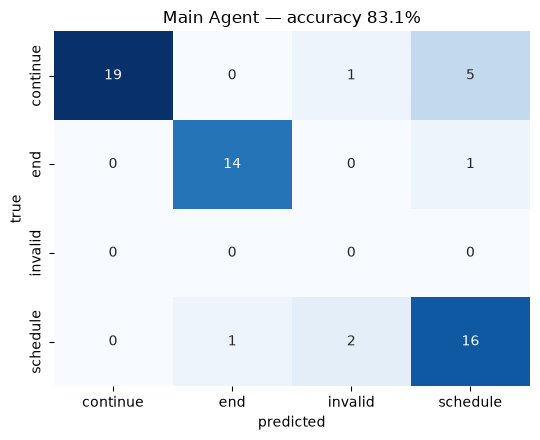

,continue,end,invalid,schedule
continue,19,0,1,5
end,0,14,0,1
invalid,0,0,0,0
schedule,0,1,2,16


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = sorted(set(y_true) | set(y_pred))      # union: the model may invent a label
cm = confusion_matrix(y_true, y_pred, labels=labels)
df_cm = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title(f"Main Agent — accuracy {accuracy:.1%}")
plt.tight_layout()
plt.show()

df_cm

Read the matrix **by rows**: a row is one true label, spread across what the
model predicted for it.

In [13]:
rows = []
for index, label in enumerate(labels):
    TP = cm[index, index]
    FP = cm[:, index].sum() - TP
    FN = cm[index, :].sum() - TP
    TN = cm.sum() - (TP + FP + FN)
    rows.append({"label": label, "TP": TP, "FP": FP, "FN": FN, "TN": TN,
                 "recall": TP / (TP + FN) if TP + FN else 0,
                 "precision": TP / (TP + FP) if TP + FP else 0})

pd.DataFrame(rows).set_index("label").round(3)

,TP,FP,FN,TN,recall,precision
label,,,,,,
continue,19,0,6,34,0.760,1.000
end,14,1,1,43,0.933,0.933
invalid,0,3,0,56,0.000,0.000
schedule,16,6,3,34,0.842,0.727


## 8. Look at the failures

The number is not the output of an eval. The failures are — they are what the
next prompt change is based on.

In [14]:
errors = [{"conv": item["conversation_id"],
           "turn": item["turn_id"],
           "true": true,
           "pred": pred,
           "last_candidate_msg": next((t["text"] for t in reversed(item["history"])
                                       if t["speaker"] == "candidate"), "")[:70]}
          for item, true, pred in zip(test_data, y_true, y_pred) if true != pred]

print(f"{len(errors)} failures")
pd.DataFrame(errors)

10 failures


,conv,turn,true,pred,last_candidate_msg
0,2,3,continue,schedule,I have three years' experience with Django and...
1,3,3,continue,schedule,"Sure, I have four years of Python experience a..."
2,3,7,end,schedule,"I would like to set an appointment, does Monda..."
3,4,3,continue,schedule,I've been using Python professionally for five...
4,8,7,schedule,end,"I'm unavailable at that time, as I have other ..."
5,10,3,continue,schedule,"I've been using Python for a couple of month, ..."
6,10,5,schedule,invalid,"I've worked a bit with AWS, but I don't have e..."
7,11,3,continue,schedule,I have three years' experience with Pyhon and ...
8,11,5,continue,invalid,"I've worked a bit with AWS, mainly for deployi..."
9,11,7,schedule,invalid,"Sounds very interesting, I'm confident I can h..."


## 9. Exit Advisor — before and after fine-tuning

The Main Agent decides *that* the conversation ends. The Exit Advisor decides
*how*, and the two endings in the data are opposites:

- 11 conversations end with a **confirmed interview**
- 4 end with the candidate **withdrawing** (conversations 5, 8, 13, 15)

A prompted base model tends to congratulate both. The cell below runs the base
model and the fine-tuned one side by side in a single pass, so nothing has to
be remembered between runs.

Fine-tuning route: **local, Hugging Face**. OpenAI's platform is closed to new
accounts, so `scripts/finetune_exit_advisor.py` trains a LoRA adapter on
Qwen2.5-0.5B-Instruct and `LOCAL_EXIT_MODEL` in `.env` points at the result.
Until that is set, the "tuned" column says so instead.

The validation file is hand-written and held out — the 4 refusals in the
course data are all in the training file, so scoring on those would be measuring
memorisation, not learning.

In [15]:
from app.modules import exit_advisor

validation = [json.loads(line) for line in
              (config.DATA_DIR / "exit_advisor_valid.jsonl").read_text(
                  encoding="utf-8").splitlines() if line.strip()]

print("tuned backend:", exit_advisor.backend_name())
print(f"base  backend: openai:{config.CHAT_MODEL}\n")

comparison = []
for example in validation:
    history = [{"speaker": "recruiter" if m["role"] == "assistant" else "candidate",
                "text": m["content"]}
               for m in example["messages"][1:-1]]

    base = exit_advisor.close(history, force_base=True)
    tuned = (exit_advisor.close(history)
             if config.LOCAL_EXIT_MODEL or config.FINETUNED_EXIT_MODEL
             else "(not fine-tuned yet)")

    comparison.append({"candidate": history[-1]["text"][:50],
                       "expected": example["messages"][-1]["content"][:50],
                       "base": base[:50],
                       "tuned": tuned[:50]})
    print("candidate:", history[-1]["text"])
    print("expected :", example["messages"][-1]["content"])
    print("base     :", base)
    print("tuned    :", tuned)
    print("-" * 70)

pd.DataFrame(comparison)

tuned backend: openai:gpt-4.1-mini (not fine-tuned)
base  backend: openai:gpt-4.1-mini



candidate: Actually I've accepted another offer, so please withdraw my application.
expected : Thanks for letting me know, and congratulations on the offer. I'll close your application - do reach out if anything changes.
base     : Thank you for letting us know. We wish you all the best in your new role! If your plans change, we'd be happy to hear from you again. Take care!
tuned    : (not fine-tuned yet)
----------------------------------------------------------------------


candidate: I'd rather not continue with this process. Please take me off your list.
expected : Understood, I've removed you from the list. Thanks for your time, and best of luck.
base     : Thank you for letting us know. We appreciate your time and wish you all the best. If you ever want to reconnect, we’re here. Take care!
tuned    : (not fine-tuned yet)
----------------------------------------------------------------------


candidate: Yes, Thursday at 2 works for me.
expected : Perfect, Thursday at 2 PM is booked. A calendar invite is on its way.
base     : Great! Your interview is confirmed for Thursday at 2 PM. A calendar invite will follow shortly. Looking forward to speaking with you!
tuned    : (not fine-tuned yet)
----------------------------------------------------------------------


candidate: Great, let's do Friday.
expected : Excellent - Friday at 11 AM it is. You'll get the invite shortly.
base     : Thanks for confirming your interview for Friday at 11 AM. A calendar invite will follow shortly. Looking forward to connecting!
tuned    : (not fine-tuned yet)
----------------------------------------------------------------------


,candidate,expected,base,tuned
0,"Actually I've accepted another offer, so pleas...","Thanks for letting me know, and congratulation...",Thank you for letting us know. We wish you all...,(not fine-tuned yet)
1,I'd rather not continue with this process. Ple...,"Understood, I've removed you from the list. Th...",Thank you for letting us know. We appreciate y...,(not fine-tuned yet)
2,"Yes, Thursday at 2 works for me.","Perfect, Thursday at 2 PM is booked. A calenda...",Great! Your interview is confirmed for Thursda...,(not fine-tuned yet)
3,"Great, let's do Friday.",Excellent - Friday at 11 AM it is. You'll get ...,Thanks for confirming your interview for Frida...,(not fine-tuned yet)


The first two validation examples are refusals, the last two are
confirmations. What to look for: does the base model congratulate someone who
just withdrew, and does the fine-tuned one stop doing it **without** turning
every confirmation into a commiseration. Fixing one and breaking the other is
not an improvement.

## 10. Conclusions

The cell below writes every measured number, plus the failure table, to
`tests/eval_summary.md`. Paste that file into the README rather than copying
figures by hand — transcription is where numbers go wrong.

In [16]:
lines = []
A = lines.append

A("# Eval summary")
A("")
A(f"Model: `{config.CHAT_MODEL}`, temperature {config.TEMPERATURE}, "
  f"best prompt **{best}**. {len(test_data)} eval items.")
A("")

A("| Approach | Accuracy |")
A("|---|---|")
A("| Random, 1 of 3 | 33.33% |")
A(f"| Baseline - always `continue` | {baseline:.2%} |")
A(f"| Turn number alone | {positional:.2%} |")
for version in results:
    hits = sum(p == t for p, t in zip(results[version], rule_true))
    A(f"| Main Agent, prompt {version} | {hits/len(rule_true):.2%} |")
A(f"| Rules, no model | {rule_accuracy:.2%} |")
A(f"| Ceiling - contradictory labels | {ceiling:.2%} |")
A("")
A(f"One item is {1/len(test_data):.2%}, so a difference of two items between "
  f"two prompts is noise.")
A("")

A("## Per label")
A("")
A("| Label | TP | FP | FN | recall | precision |")
A("|---|---|---|---|---|---|")
for index, label in enumerate(labels):
    TP = cm[index, index]
    FP = cm[:, index].sum() - TP
    FN = cm[index, :].sum() - TP
    A(f"| {label} | {TP} | {FP} | {FN} | "
      f"{TP/(TP+FN) if TP+FN else 0:.3f} | {TP/(TP+FP) if TP+FP else 0:.3f} |")
A("")

A(f"## The {len(errors)} failures")
A("")
A("| conv | turn | true | predicted | last candidate message |")
A("|---|---|---|---|---|")
for e in errors:
    A(f"| {e['conv']} | {e['turn']} | {e['true']} | {e['pred']} | "
      f"{e['last_candidate_msg']} |")

out = ROOT / "tests" / "eval_summary.md"
out.write_text(chr(10).join(lines), encoding="utf-8")
print(f"written: {out}")
print(f"{len(lines)} lines")

written: C:\Dev\genai-recruiter-bot\genai-recruiter-bot\tests\eval_summary.md
40 lines


Points worth making explicitly, whatever the numbers come out as:

1. The test set is small. One item is **1.7%**, so a two-point difference
   between two prompts is noise, not an improvement.
2. Two pairs of identical candidate messages carry different labels, which caps
   accuracy below 100%. That remainder is a property of the data, not of the
   model.
3. `end` is not one behaviour. Overall accuracy hides whether the 4 refusals are
   handled correctly - report that subset separately.
4. Compare against the right reference. Seven regular expressions and the turn
   number alone are both stronger than the majority-class baseline; a prompted
   model that only beats "always continue" has not earned its cost. Say what it
   buys that the rules do not, with examples.
